# H02. 펌프 누설에 따라 유량·효율 계수가 다른가

| 항목 | 내용 |
|---|---|
| 질문 | 펌프에 누설이 생기면(0 → 1 → 2) 유량과 효율 계수가 달라질까? |
| 귀무가설 H0 | 펌프 누설 3개 그룹의 FS1_mean(유량), SE_mean(효율 계수) 분포는 같다 |
| 대립가설 H1 | 적어도 한 그룹의 분포가 다르다 |
| 검정 | Kruskal-Wallis(특징 2개 → Holm 보정) → Dunn, 효과 크기 ε² |
| 출처 (EDA) | F09, F25 |
| 데이터 | FS1_mean, SE_mean × pump_leak |
| 왜 중요한가 | 펌프 진단에 쓸 센서 근거, 누설 1과 2를 구분할 수 있는지 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

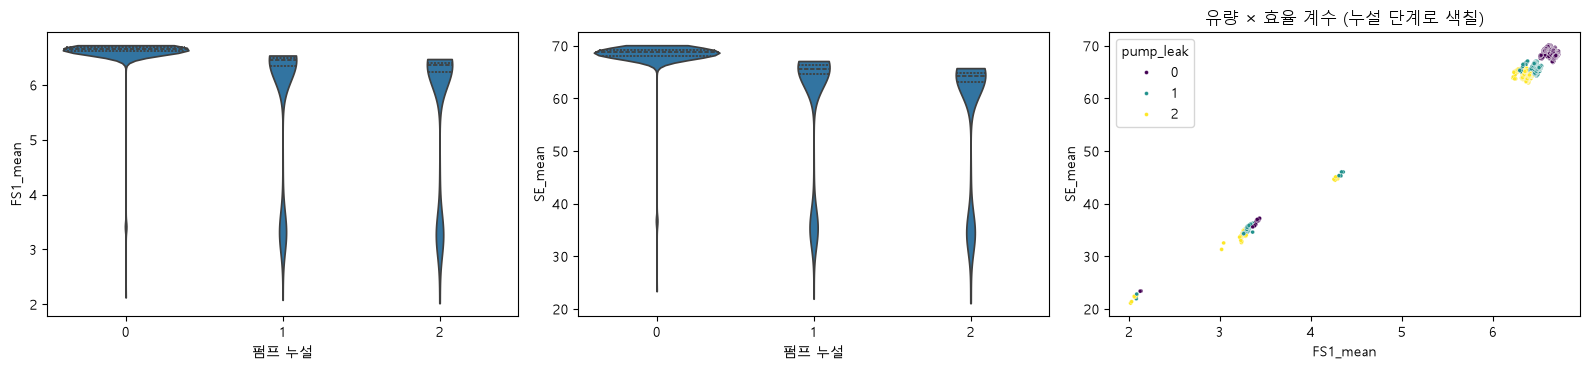

In [2]:
c = "pump_leak"; FS = ["FS1_mean", "SE_mean"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, f in zip(axes[:2], FS):
    sns.violinplot(data=cyc, x=c, y=f, ax=ax, inner="quartile", cut=0); ax.set_xlabel(COMP[c])
sns.scatterplot(data=cyc, x="FS1_mean", y="SE_mean", hue=c, s=8, ax=axes[2], palette="viridis")
axes[2].set_title("유량 × 효율 계수 (누설 단계로 색칠)")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 누설 0은 뚜렷이 갈리고, 1과 2는 가깝지만 중심이 다릅니다. 두 특징을 같이 보면(오른쪽) 세 그룹이 더 잘 갈립니다.

## 2. 기술통계

In [3]:
display(cyc.groupby(c)[FS].describe().T.round(2))

pump_leak             0       1       2
FS1_mean count  1221.00  492.00  492.00
         mean      6.60    5.79    5.61
         std       0.38    1.30    1.35
         min       2.12    2.08    2.02
         25%       6.61    6.34    6.23
         50%       6.65    6.46    6.36
         75%       6.68    6.49    6.39
         max       6.72    6.54    6.47
SE_mean  count  1221.00  492.00  492.00
         mean     68.26   59.39   57.12
         std       3.82   12.60   13.07
         min      23.37   21.94   21.09
         25%      68.08   64.65   63.07
         50%      68.76   65.67   64.21
         75%      69.16   66.36   64.84
         max      70.10   67.10   65.75

## 3. 가정 확인 → 검정 방법 고르기

특징 2개 각각 그룹별 정규성(D'Agostino)과 등분산(Levene)을 봅니다.

[FS1_mean]


,그룹,n,왜도,K2,정규성_p,정규분포
0,0,1221,-8.93,1808.3,0.00e+00,아니오
1,1,492,-1.43,101.5,8.94e-23,아니오
2,2,492,-1.25,86.4,1.72e-19,아니오


Levene W = 144.91, p = 7.54e-60 → 등분산: 아니오

[SE_mean]


,그룹,n,왜도,K2,정규성_p,정규분포
0,0,1221,-8.67,1779.2,0.00e+00,아니오
1,1,492,-1.44,102.2,6.42e-23,아니오
2,2,492,-1.26,86.2,1.87e-19,아니오


Levene W = 141.93, p = 1.05e-58 → 등분산: 아니오



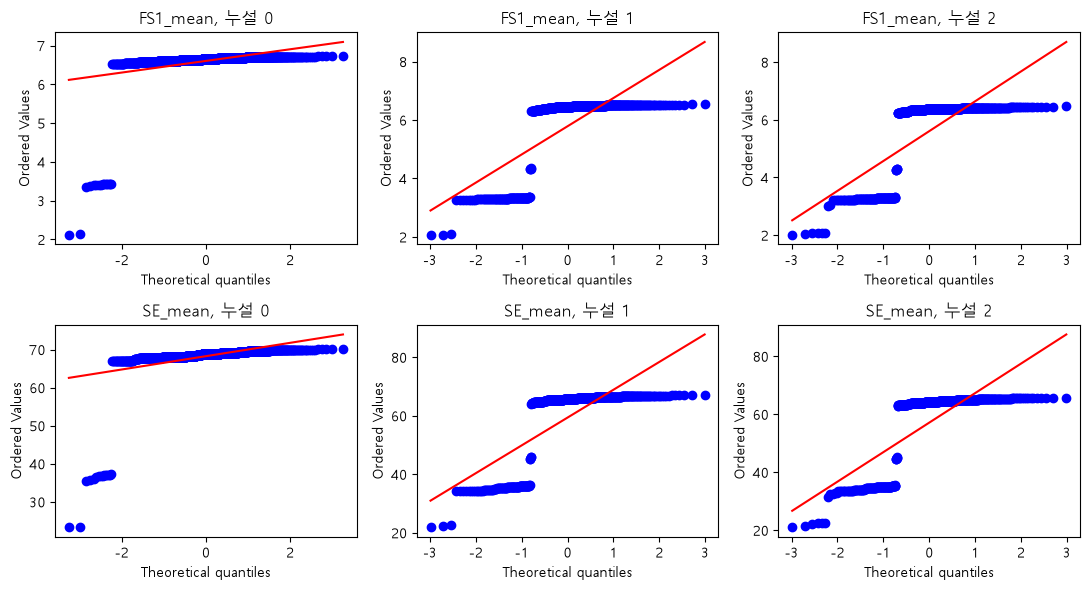

선택한 검정: Kruskal-Wallis (정규성·등분산이 성립하지 않으므로)


In [4]:
for f in FS:
    tab, lev = assumption_table(cyc[f], cyc[c])
    print(f"[{f}]"); display(tab.style.format({"왜도": "{:.2f}", "K2": "{:.1f}", "정규성_p": "{:.2e}"}))
    print(f"Levene W = {lev['W']:.2f}, p = {lev['p']:.2e} → 등분산: {lev['등분산']}\n")
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for i, f in enumerate(FS):
    for ax, gv in zip(axes[i], sorted(cyc[c].unique())):
        stats.probplot(cyc.loc[cyc[c] == gv, f], dist="norm", plot=ax); ax.set_title(f"{f}, 누설 {gv}")
plt.tight_layout(); plt.show()
print("선택한 검정: Kruskal-Wallis (정규성·등분산이 성립하지 않으므로)")

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,FS1_mean,원값,0.0021,0.010,추세·구조변화(둘 다 기각)
1,FS1_mean,1차 차분,0.0000,0.100,정상
2,SE_mean,원값,0.0008,0.010,추세·구조변화(둘 다 기각)
3,SE_mean,1차 차분,0.0000,0.100,정상


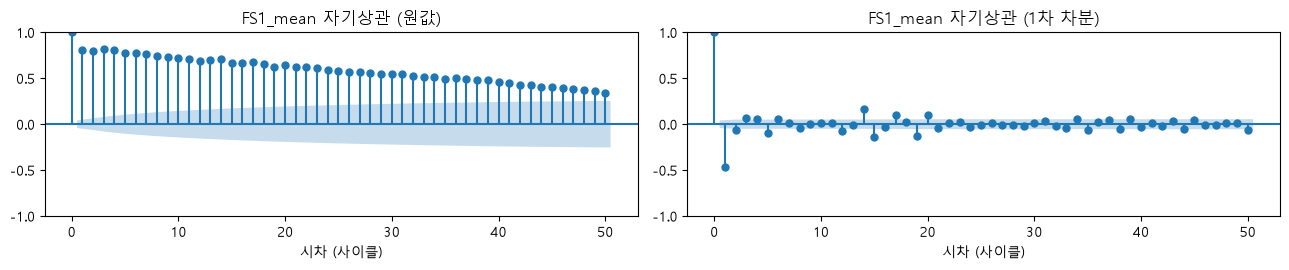

In [5]:
st = stationarity(cyc, ['FS1_mean', 'SE_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['FS1_mean'], "FS1_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['FS1_mean'].diff(), "FS1_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값)

특징이 2개라 검정을 두 번 하므로 Holm 보정을 합니다.

In [6]:
res = pd.DataFrame([dict(특징=f, **kruskal_test(cyc[f], cyc[c])) for f in FS])
res["p_holm"] = holm(res["p"]); res["효과"] = res["eps2"].map(size_label)
display(res.style.format({"H": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "eps2": "{:.3f}"}))

,특징,H,df,p,eps2,n,p_holm,효과
0,FS1_mean,1609.1,2,0.00e+00,0.730,2205,0.00e+00,큼
1,SE_mean,1618.2,2,0.00e+00,0.734,2205,0.00e+00,큼


## 6. 사후검정·효과 크기

가장 헷갈리기 쉬운 **누설 1 vs 2**가 구분되는지 특히 봅니다.

In [7]:
for f in FS:
    print(f"[{f}]"); display(dunn_test(cyc[f], cyc[c]).style.format({"z": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))

[FS1_mean]


,쌍,z,p,p_holm,유의
0,0 vs 1,27.97,3.66e-172,7.33e-172,예
1,0 vs 2,35.57,3.48e-277,1.04e-276,예
2,1 vs 2,6.37,1.91e-10,1.91e-10,예


[SE_mean]


,쌍,z,p,p_holm,유의
0,0 vs 1,27.57,2.67e-167,5.35e-167,예
1,0 vs 2,35.98,1.83e-283,5.49e-283,예
2,1 vs 2,7.04,1.87e-12,1.87e-12,예


## 7. 블록 평균으로 재확인

In [8]:
blk = []
for f in FS:
    b = block_means(cyc, f, c); rb = kruskal_test(b[f], b[c]); blk.append(rb)
    print(f"{f}: 블록 {len(b)}개, H({rb['df']}) = {rb['H']:.1f}, p = {rb['p']:.3g}, ε² = {rb['eps2']:.3f}")

FS1_mean: 블록 80개, H(2) = 52.9, p = 3.24e-12, ε² = 0.670
SE_mean: 블록 80개, H(2) = 56.8, p = 4.55e-13, ε² = 0.719


## 8. 최종 판정

In [9]:
final = pd.DataFrame([dict(가설="H02", 특징=f, 통계량=f"H({res.df[i]}) = {res.H[i]:.1f}", p_holm=res.p_holm[i],
    효과크기=f"ε² = {res.eps2[i]:.3f} ({size_label(res.eps2[i])})", 블록평균_p=blk[i]["p"],
    판정="H0 기각" if (res.p_holm[i] < ALPHA and blk[i]["p"] < ALPHA) else "H0 유지") for i, f in enumerate(FS)])
display(final)
save_result("H02", title="펌프 누설 → 유량·효율 계수", test="Kruskal-Wallis (2개, Holm)",
            stat=" / ".join(final.통계량), p=float(final.p_holm.max()), effect=" / ".join(final.효과크기),
            verdict="H0 기각" if (final.판정 == "H0 기각").all() else "일부 H0 유지")

,가설,특징,통계량,p_holm,효과크기,블록평균_p,판정
0,H02,FS1_mean,H(2) = 1609.1,0.0,ε² = 0.730 (큼),3.237175e-12,H0 기각
1,H02,SE_mean,H(2) = 1618.2,0.0,ε² = 0.734 (큼),4.551938e-13,H0 기각


저장: results/H02.json


## 9. 해석과 결정

- 유량(FS1)과 효율 계수(SE) 모두 누설 단계에 따라 크게 다릅니다(ε² ≈ 0.73, 큼). 블록 평균으로도 결론이 같습니다.
- 가장 어려운 **누설 1 vs 2도 통계적으로 구분**됩니다(Dunn, Holm 보정 후 p < .001).
- **결정:** 펌프 진단의 핵심 입력은 FS1과 SE입니다. 판단 근거 화면(FR-06)에도 이 두 센서가 상위에 나와야 정상입니다.